In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('AB_NYC_2019.csv')

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1.0,9.0,2018-10-19,0.21,6.0,365.0
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1.0,45.0,2019-05-21,0.38,2.0,355.0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3.0,0.0,NaN,NaN,1.0,365.0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1.0,270.0,2019-07-05,4.64,1.0,194.0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10.0,9.0,2018-11-19,0.10,1.0,0.0


In [4]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
36329,28910899,"Private room in large, central Nolita penthouse!",153154549,Sarah,Manhattan,Nolita,40.72135,-73.99426,Private room,140.0,3.0,2.0,2018-10-15,0.22,1.0,0.0
36330,28910978,Artistic house with murals,52044518,Veronica,Queens,East Elmhurst,40.76173,-73.87417,Private room,65.0,1.0,58.0,2019-07-08,6.19,1.0,47.0
36331,28911697,Cozy Artist Room,70230403,Sonya,Brooklyn,Bushwick,40.69677,-73.92688,Private room,57.0,1.0,1.0,2018-10-22,0.12,1.0,0.0
36332,28911775,LUXURY PRIVATE BEDROOM & Bath Mins from JFK,217621677,Joseph,Queens,St. Albans,40.68754,-73.77488,Private room,50.0,1.0,16.0,2019-07-07,1.78,4.0,137.0
36333,28911830,Charming redbrick Bronx Villa,19108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36334 entries, 0 to 36333
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              36334 non-null  int64  
 1   name                            36318 non-null  object 
 2   host_id                         36334 non-null  int64  
 3   host_name                       36313 non-null  object 
 4   neighbourhood_group             36333 non-null  object 
 5   neighbourhood                   36333 non-null  object 
 6   latitude                        36333 non-null  float64
 7   longitude                       36333 non-null  float64
 8   room_type                       36333 non-null  object 
 9   price                           36333 non-null  float64
 10  minimum_nights                  36333 non-null  float64
 11  number_of_reviews               36333 non-null  float64
 12  last_review                     

In [6]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print('Numerical Columns:', numerical_cols)
print('Categorical Columns:', categorical_cols)

Numerical Columns: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical Columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [7]:
missing_data = df.isnull().sum()
missing_percentages = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_data, 'Percentage': missing_percentages})
display(missing_df[missing_df['Missing Values'] > 0])

,Missing Values,Percentage
name,16,0.044036
host_name,21,0.057797
neighbourhood_group,1,0.002752
neighbourhood,1,0.002752
latitude,1,0.002752
longitude,1,0.002752
room_type,1,0.002752
price,1,0.002752
minimum_nights,1,0.002752
number_of_reviews,1,0.002752


In [8]:
df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review'], inplace=True)

In [9]:
df['reviews_per_month'].fillna(0, inplace=True)

In [11]:

print(df.isnull().sum())

neighbourhood_group               1
neighbourhood                     1
latitude                          1
longitude                         1
room_type                         1
price                             1
minimum_nights                    1
number_of_reviews                 1
reviews_per_month                 0
calculated_host_listings_count    1
availability_365                  1
dtype: int64


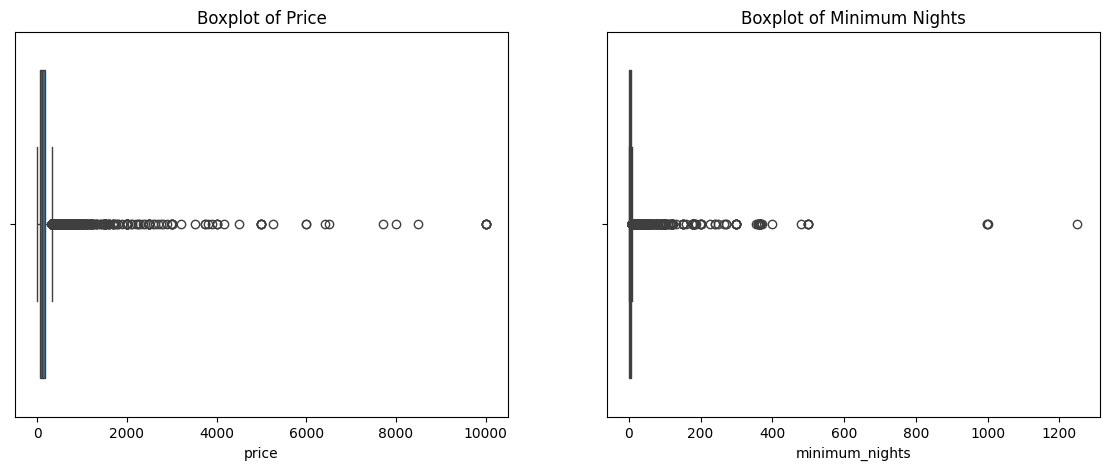

In [12]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['minimum_nights'])
plt.title('Boxplot of Minimum Nights')
plt.show()

In [13]:
price_95 = df['price'].quantile(0.95)
min_nights_95 = df['minimum_nights'].quantile(0.95)

In [14]:
df_cleaned = df[(df['price'] <= price_95) & (df['minimum_nights'] <= min_nights_95)].copy()
print(f'Original shape: {df.shape}')
print(f'Shape after outlier treatment: {df_cleaned.shape}')

Original shape: (36334, 11)
Shape after outlier treatment: (34004, 11)


In [15]:
df_cleaned.drop(columns=['neighbourhood'], inplace=True)

In [16]:
df_encoded = pd.get_dummies(df_cleaned, columns=['neighbourhood_group', 'room_type'], drop_first=True)

In [17]:
display(df_encoded.head())

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149.0,1.0,9.0,0.21,6.0,365.0,True,False,False,False,True,False
1,40.75362,-73.98377,225.0,1.0,45.0,0.38,2.0,355.0,False,True,False,False,False,False
2,40.80902,-73.94190,150.0,3.0,0.0,0.00,1.0,365.0,False,True,False,False,True,False
3,40.68514,-73.95976,89.0,1.0,270.0,4.64,1.0,194.0,True,False,False,False,False,False
4,40.79851,-73.94399,80.0,10.0,9.0,0.10,1.0,0.0,False,True,False,False,False,False


In [20]:
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f'Training set size: X={X_train.shape}, y={y_train.shape}')
print(f'Testing set size: X={X_test.shape}, y={y_test.shape}')

Training set size: X=(27203, 13), y=(27203,)
Testing set size: X=(6801, 13), y=(6801,)


In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Initialize and fit Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Generate price predictions
y_pred = model.predict(X_test)

# Calculate key metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R-Squared (R2) Score: {r2:.4f}')
print(f'Mean Absolute Error (MAE): ${mae:.2f}')
print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f'Root Mean Squared Error (RMSE): ${rmse:.2f}')

R-Squared (R2) Score: 0.4542
Mean Absolute Error (MAE): $36.10
Mean Squared Error (MSE): 2415.30
Root Mean Squared Error (RMSE): $49.15


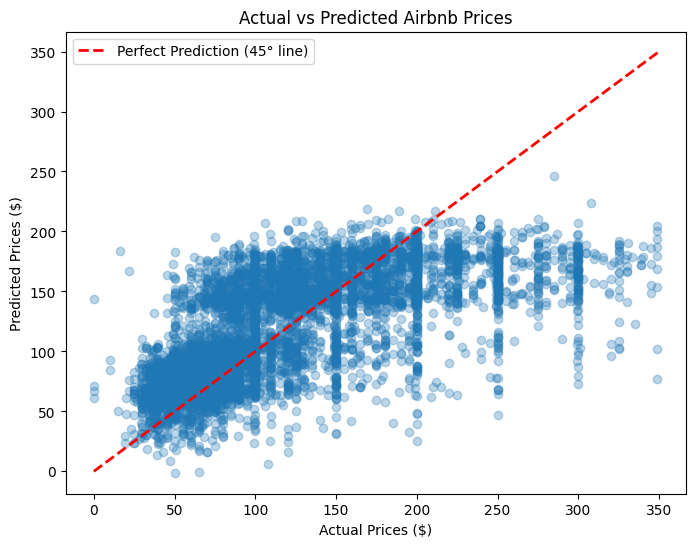

In [26]:
# Scatter plot of Actual vs. Predicted Prices with a 45-degree line
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], color='red', linestyle='--', lw=2, label='Perfect Prediction (45° line)')
plt.xlabel('Actual Prices ($)')
plt.ylabel('Predicted Prices ($)')
plt.title('Actual vs Predicted Airbnb Prices')
plt.legend()
plt.show()

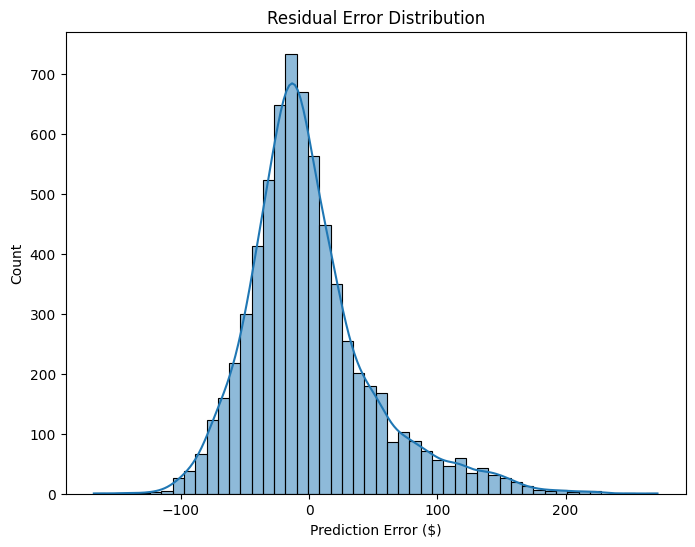

In [27]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, bins=50)
plt.xlabel('Prediction Error ($)')
plt.title('Residual Error Distribution')
plt.show()